# Forcing sensitivity

Running MIKE setups on local machine for 200 timesteps

In [22]:
import mikeio
import numpy as np

In [23]:
fldr = r"C:\Users\frtp\Source\WaterBench-MIKE3HD-Oresund"

In [24]:
fn_base = fldr +r"\model\Oresund_HD_short_baseline.m3fm - Result Files\3D.dfsu"

ds_base = mikeio.read(fn_base)

In [25]:
ds_base

<mikeio.Dataset>
dims: (time:209, element:40500)
time: 2023-01-01 00:00:00 - 2023-01-09 16:00:00 (209 records)
geometry: Dfsu3DSigmaZ (40500 elements, 26434 nodes)
items:
  0:  U velocity <u velocity component> (meter per sec)
  1:  V velocity <v velocity component> (meter per sec)
  2:  W velocity <w velocity component> (meter per sec)
  3:  Density <Density> (kg per meter pow 3)
  4:  Temperature <Temperature> (degree Celsius)
  5:  Salinity <Salinity> (PSU)

In [26]:
print("Time:", ds_base[0].time[0], "to", ds_base[0].time[-1])
print(ds_base[0].name,":")
print("     Max:", np.nanmax(ds_base[0].values))
print("     Min:", np.nanmin(ds_base[0].values))
print("     Mean:", np.nanmean(ds_base[0].values))
print(ds_base[1].name,":")
print("     Max:", np.nanmax(ds_base[1].values))
print("     Min:", np.nanmin(ds_base[1].values))
print("     Mean:", np.nanmean(ds_base[1].values))
print(ds_base[2].name,":")
print("     Max:", np.nanmax(ds_base[2].values))
print("     Min:", np.nanmin(ds_base[2].values))
print("     Mean:", np.nanmean(ds_base[2].values))

Time: 2023-01-01 00:00:00 to 2023-01-09 16:00:00
U velocity :
     Max: 0.97049445
     Min: -1.5715196
     Mean: -0.0041474397
V velocity :
     Max: 2.1379006
     Min: -2.4176667
     Mean: 0.057274822
W velocity :
     Max: 0.007018451
     Min: -0.005725062
     Mean: -4.812008e-07


### Ice
Removing ice should result in no differences, since the ice input is always zero.

In [27]:
forc_ice = fldr + r"\input\ERA5_ICE.dfs2"

ds_ice = mikeio.read(forc_ice)
print("Time:", ds_ice[0].time[0], "to", ds_ice[0].time[-1])
print("Max:", np.nanmax(ds_ice[0].values))
print("Min:", np.nanmin(ds_ice[0].values))
print("Mean:", np.nanmean(ds_ice[0].values))

Time: 2023-01-01 00:00:00 to 2025-12-31 23:00:00
Max: 0.0
Min: 0.0
Mean: 0.0


In [28]:
# Load model run without ice

fn_no_ice = fldr +r"\model\Oresund_HD_no_ice.m3fm - Result Files\3D.dfsu"
ds_no_ice = mikeio.read(fn_no_ice)

err = ds_base[0].sel(time=slice(ds_no_ice.time[0], ds_no_ice.time[-1])).values - ds_no_ice[0].values
print("Error (base - no ice):")
print("     Max:", np.nanmax(err))
print("     Min:", np.nanmin(err))
print("     Mean:", np.nanmean(err))
print("     Median:", np.nanmedian(err))
print("     std:", np.nanstd(err))

Error (base - no ice):
     Max: 0.0
     Min: 0.0
     Mean: 0.0
     Median: 0.0
     std: 0.0


##### Conclusion: Ice can be removed

### Relative humidity
Using default value of 88% instead of having it vary in time and space.

In [29]:
forc = fldr + r"\input\ERA5_RH2.dfs2"

ds_forc = mikeio.read(forc,time=slice(ds_base[0].time[0], ds_base[0].time[-1]))
print("SHORT PERIOD: Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Max:", np.nanmax(ds_forc[0].values))
print("Min:", np.nanmin(ds_forc[0].values))
print("Mean:", np.nanmean(ds_forc[0].values))
print("Median:", np.nanmedian(ds_forc[0].values))
print("std:", np.nanstd(ds_forc[0].values))


ds_forc = mikeio.read(forc)
print("FULL PERIOD: Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Max:", np.nanmax(ds_forc[0].values))
print("Min:", np.nanmin(ds_forc[0].values))
print("Mean:", np.nanmean(ds_forc[0].values))
print("Median:", np.nanmedian(ds_forc[0].values))
print("std:", np.nanstd(ds_forc[0].values))

SHORT PERIOD: Time: 2023-01-01 00:00:00 to 2023-01-09 16:00:00
Max: 100.01837
Min: 70.38665
Mean: 91.19193
Median: 91.59984
std: 4.926674
FULL PERIOD: Time: 2023-01-01 00:00:00 to 2025-12-31 23:00:00
Time: 2023-01-01 00:00:00 to 2025-12-31 23:00:00
Max: 100.02545
Min: 17.378637
Mean: 81.69606
Median: 84.07287
std: 11.992831


In [30]:
fn_no_forc = fldr +r"\model\Oresund_HD_no_RH2.m3fm - Result Files\3D.dfsu"
ds_no_forc = mikeio.read(fn_no_forc)

err = abs(ds_base[0].values - ds_no_forc[0].values)
print("Error (base - no RH2 forcing):")
print("     Max:", np.nanmax(err))
print("     Min:", np.nanmin(err))
print("     Mean:", np.nanmean(err))
print("     Median:", np.nanmedian(err))
print("     std:", np.nanstd(err))

Error (base - no RH2 forcing):
     Max: 0.10361353
     Min: 0.0
     Mean: 5.1740455e-05
     Median: 2.4691224e-05
     std: 0.00030470383


### Cloud cover

In [31]:
forc = fldr + r"\input\ERA5_CLEARNESS.dfs2"

ds_forc = mikeio.read(forc,time=slice(ds_base[0].time[0], ds_base[0].time[-1]))
print("SHORT PERIOD: Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Max:", np.nanmax(ds_forc[0].values))
print("Min:", np.nanmin(ds_forc[0].values))
print("Mean:", np.nanmean(ds_forc[0].values))
print("Median:", np.nanmedian(ds_forc[0].values))
print("std:", np.nanstd(ds_forc[0].values))


ds_forc = mikeio.read(forc)
print("FULL PERIOD: Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Max:", np.nanmax(ds_forc[0].values))
print("Min:", np.nanmin(ds_forc[0].values))
print("Mean:", np.nanmean(ds_forc[0].values))
print("Median:", np.nanmedian(ds_forc[0].values))
print("std:", np.nanstd(ds_forc[0].values))

SHORT PERIOD: Time: 2023-01-01 00:00:00 to 2023-01-09 16:00:00
Max: 99.80469
Min: 0.0
Mean: 13.40624
Median: 0.12207031
std: 24.147478
FULL PERIOD: Time: 2023-01-01 00:00:00 to 2025-12-31 23:00:00
Time: 2023-01-01 00:00:00 to 2025-12-31 23:00:00
Max: 100.0
Min: 0.0
Mean: 34.894325
Median: 18.54248
std: 37.057747


In [32]:

fn_no_forc = fldr +r"\model\Oresund_HD_no_clearness.m3fm - Result Files\3D.dfsu"
ds_no_forc = mikeio.read(fn_no_forc)

err = abs(ds_base[0].values - ds_no_forc[0].values)
print("Error (base - no clearness forcing):")
print("     Max:", np.nanmax(err))
print("     Min:", np.nanmin(err))
print("     Mean:", np.nanmean(err))
print("     Median:", np.nanmedian(err))
print("     std:", np.nanstd(err))

Error (base - no clearness forcing):
     Max: 0.078372866
     Min: 0.0
     Mean: 0.00045061257
     Median: 0.00020587444
     std: 0.0010634963


### Precipitation

In [33]:
forc = fldr + r"\input\ERA5_PRECIPITATION.dfs2"

ds_forc = mikeio.read(forc,time=slice(ds_base[0].time[0], ds_base[0].time[-1]))
print("SHORT PERIOD: Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Max:", np.nanmax(ds_forc[0].values))
print("Min:", np.nanmin(ds_forc[0].values))
print("Mean:", np.nanmean(ds_forc[0].values))
print("Median:", np.nanmedian(ds_forc[0].values))
print("std:", np.nanstd(ds_forc[0].values))


ds_forc = mikeio.read(forc)
print("FULL PERIOD: Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Time:", ds_forc[0].time[0], "to", ds_forc[0].time[-1])
print("Max:", np.nanmax(ds_forc[0].values))
print("Min:", np.nanmin(ds_forc[0].values))
print("Mean:", np.nanmean(ds_forc[0].values))
print("Median:", np.nanmedian(ds_forc[0].values))
print("std:", np.nanstd(ds_forc[0].values))

SHORT PERIOD: Time: 2023-01-01 00:00:00 to 2023-01-09 16:00:00
Max: 174.42151
Min: 0.0
Mean: 9.9877825
Median: 0.9984255
std: 20.58327
FULL PERIOD: Time: 2023-01-01 00:00:00 to 2025-12-31 23:00:00
Time: 2023-01-01 00:00:00 to 2025-12-31 23:00:00
Max: 483.1931
Min: 0.0
Mean: 3.8756368
Median: 0.034439564
std: 13.418496


In [34]:
fn_no_forc = fldr +r"\model\Oresund_HD_no_precipitation.m3fm - Result Files\3D.dfsu"
ds_no_forc = mikeio.read(fn_no_forc)

err = abs(ds_base[0].values - ds_no_forc[0].values)
print("Error (base - no precipitation forcing):")
print("     Max:", np.nanmax(err))
print("     Min:", np.nanmin(err))
print("     Mean:", np.nanmean(err))
print("     Median:", np.nanmedian(err))
print("     std:", np.nanstd(err))

Error (base - no precipitation forcing):
     Max: 0.13328558
     Min: 0.0
     Mean: 0.0008100142
     Median: 0.00040800124
     std: 0.0014693172


## Visualizations
Comparison of each sensitivity run (one forcing replaced by its constant default) against the short baseline. Ice is left out since it has no effect. Differences are *sensitivity run − baseline*. RMS values are taken over all mesh elements (not volume weighted).

In [35]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

def result_file(run, fname):
    return fldr + rf"\model\Oresund_HD_{run}.m3fm - Result Files\{fname}"

# Sensitivity runs: one forcing removed at a time (ice excluded, it has no effect)
runs = {
    "no_RH2":           dict(label="No relative humidity", forcing="RH2",           const=88.0, color="#2a78d6"),
    "no_clearness":     dict(label="No clearness",         forcing="CLEARNESS",     const=70.0, color="#eb6834"),
    "no_precipitation": dict(label="No precipitation",     forcing="PRECIPITATION", const=0.0,  color="#1baf7a"),
}

items_3d = ["Temperature", "Salinity", "Density", "U velocity", "V velocity"]

def load(run):
    ds3 = mikeio.read(result_file(run, "3D.dfsu"), items=items_3d)
    ds2 = mikeio.read(result_file(run, "2D.dfsu"), items=["Surface elevation"])
    return {
        "Temperature": ds3["Temperature"],
        "Salinity": ds3["Salinity"],
        "Density": ds3["Density"],
        "Current speed": (ds3["U velocity"] ** 2 + ds3["V velocity"] ** 2) ** 0.5,
        "Surface elevation": ds2["Surface elevation"],
    }

base = load("short_baseline")
sens = {run: load(run) for run in runs}

units = {
    "Temperature": "°C",
    "Salinity": "PSU",
    "Density": "kg/m³",
    "Current speed": "m/s",
    "Surface elevation": "m",
}

# Differences (sensitivity run - baseline)
diff = {run: {var: sens[run][var] - base[var] for var in units} for run in runs}

plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "lines.linewidth": 2, "legend.frameon": False,
})
# Diverging colormap: blue - neutral grey - red
cmap_div = LinearSegmentedColormap.from_list(
    "div", ["#0d366b", "#3987e5", "#f0efec", "#e66767", "#8c1f1f"])


### Overview: all forcings, all variables
RMS difference to the baseline through time.

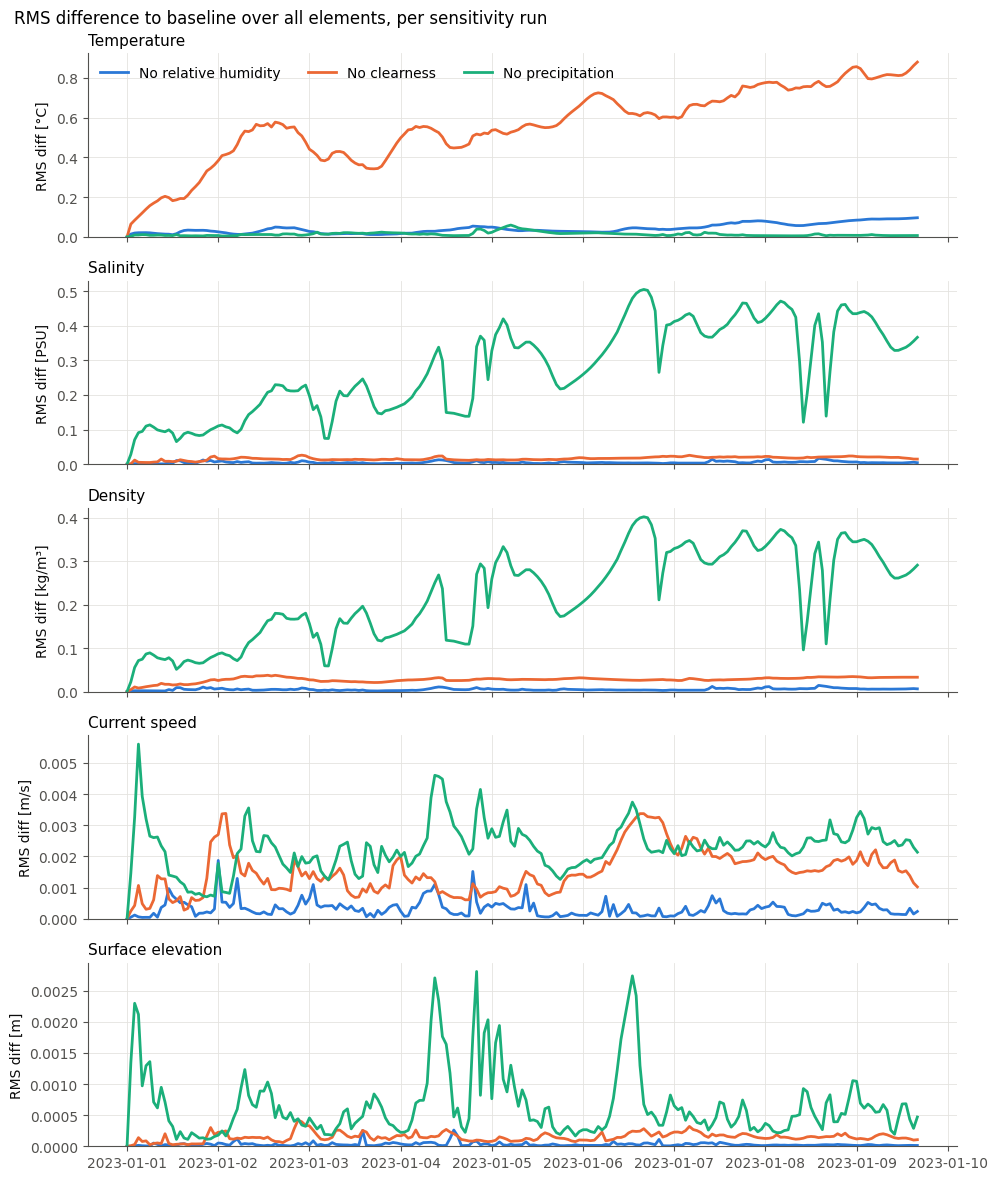

In [36]:
fig, axes = plt.subplots(len(units), 1, figsize=(10, 12), sharex=True)
for ax, var in zip(axes, units):
    for run, meta in runs.items():
        d = diff[run][var]
        rms = np.sqrt(np.nanmean(d.values ** 2, axis=1))
        ax.plot(d.time, rms, color=meta["color"], label=meta["label"])
    ax.set_title(var, loc="left", fontsize=11)
    ax.set_ylabel(f"RMS diff [{units[var]}]")
    ax.set_ylim(bottom=0)
axes[0].legend(loc="upper left", ncols=3)
fig.suptitle("RMS difference to baseline over all elements, per sensitivity run", x=0.01, ha="left")
fig.tight_layout()
plt.show()


Relative to the variability of each variable: the RMS difference divided by the spatial standard deviation of the baseline field at the same timestep. This is more informative than dividing by the field's magnitude, which is dominated by the mean (e.g. density ≈ 1010 kg/m³).

C:\Users\frtp\AppData\Local\Temp\ipykernel_39332\2768010057.py:9: RuntimeWarning: invalid value encountered in divide
  ax.plot(d.time, rms / std, color=meta["color"], label=meta["label"])


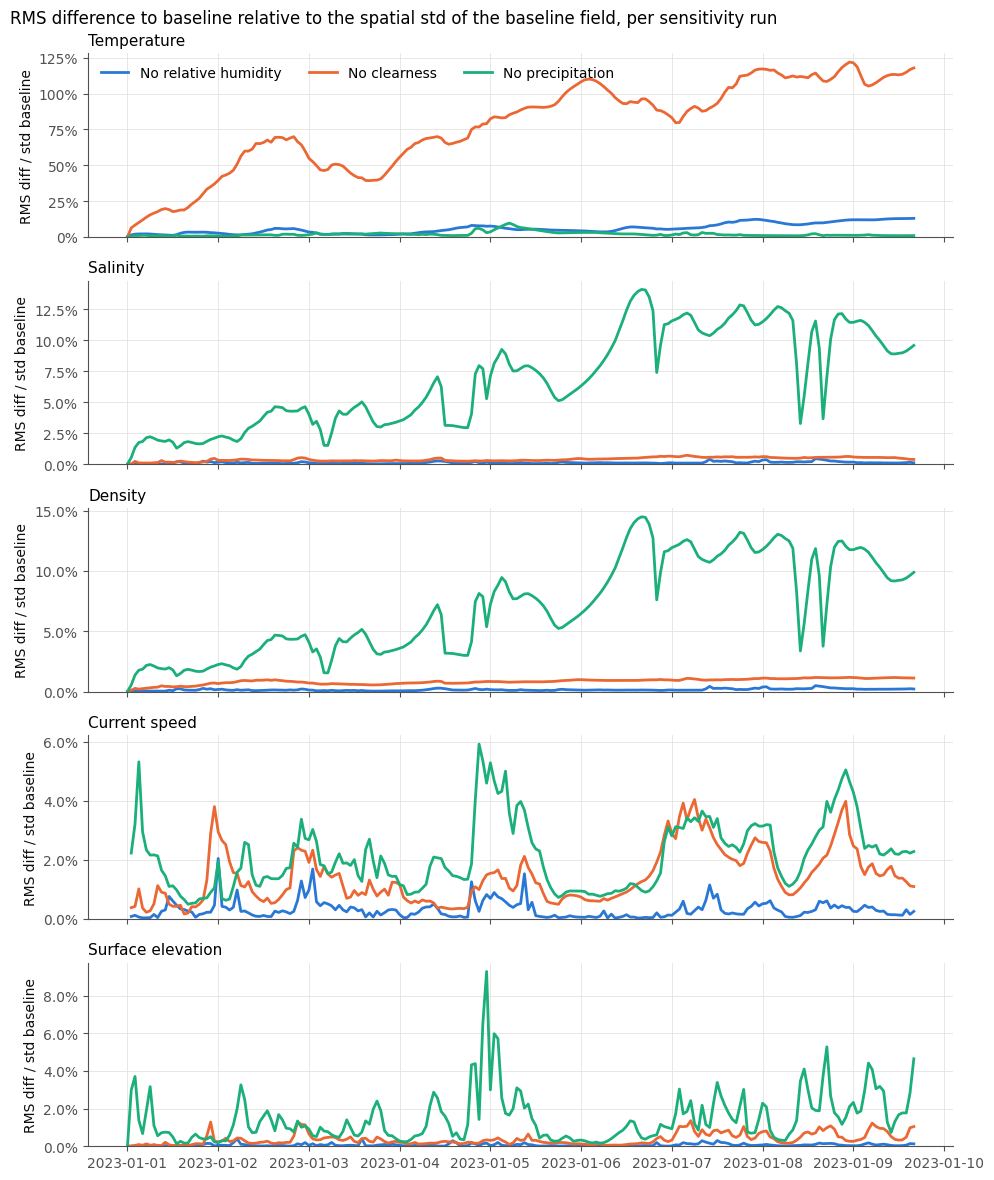

In [37]:
# Same as above, but relative to the variability of the state variable:
# RMS(sensitivity - baseline) / std(baseline), both over all elements at each timestep
fig, axes = plt.subplots(len(units), 1, figsize=(10, 12), sharex=True)
for ax, var in zip(axes, units):
    std = np.nanstd(base[var].values, axis=1)
    for run, meta in runs.items():
        d = diff[run][var]
        rms = np.sqrt(np.nanmean(d.values ** 2, axis=1))
        ax.plot(d.time, rms / std, color=meta["color"], label=meta["label"])
    ax.set_title(var, loc="left", fontsize=11)
    ax.set_ylabel("RMS diff / std baseline")
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=None))
    ax.set_ylim(bottom=0)
axes[0].legend(loc="upper left", ncols=3)
fig.suptitle("RMS difference to baseline relative to the spatial std of the baseline field, per sensitivity run",
             x=0.01, ha="left")
fig.tight_layout()
plt.show()


### Summary: impact at the end of the simulation
RMS difference at the last timestep, normalised by the baseline's spatial standard deviation, so variables with different units can be compared.

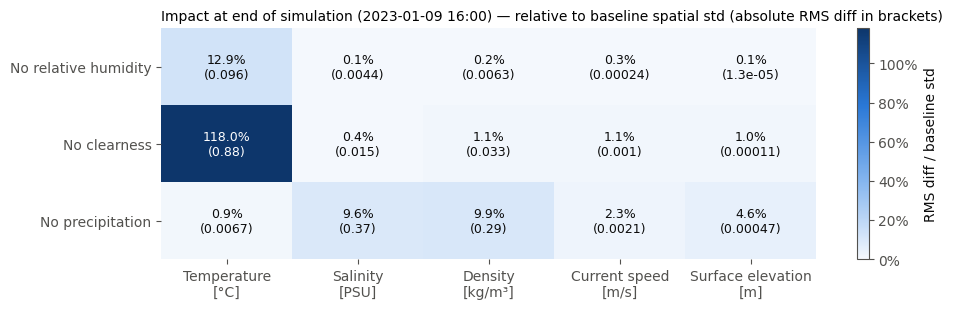

In [38]:
# Impact at the end of the simulation, normalised by the spatial variability of the baseline
t_end = -1
rel = pd.DataFrame(
    {var: [np.sqrt(np.nanmean(diff[run][var].values[t_end] ** 2)) / np.nanstd(base[var].values[t_end])
           for run in runs] for var in units},
    index=[m["label"] for m in runs.values()],
)
absval = pd.DataFrame(
    {var: [np.sqrt(np.nanmean(diff[run][var].values[t_end] ** 2)) for run in runs] for var in units},
    index=rel.index,
)

fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(rel.values, cmap=LinearSegmentedColormap.from_list("seq", ["#f4f8fd", "#86b6ef", "#2a78d6", "#0d366b"]),
               vmin=0, aspect="auto")
ax.set_xticks(range(len(units)), [f"{v}\n[{units[v]}]" for v in units])
ax.set_yticks(range(len(runs)), rel.index)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(rel.shape[0]):
    for j in range(rel.shape[1]):
        val = rel.values[i, j]
        ax.text(j, i, f"{val:.1%}\n({absval.values[i, j]:.2g})", ha="center", va="center", fontsize=9,
                color="white" if val > 0.6 * np.nanmax(rel.values) else "#0b0b0b")
fig.colorbar(im, ax=ax, label="RMS diff / baseline std", format=matplotlib.ticker.PercentFormatter(1.0))
ax.set_title(f"Impact at end of simulation ({base['Temperature'].time[t_end]:%Y-%m-%d %H:%M}) — "
             "relative to baseline spatial std (absolute RMS diff in brackets)", loc="left", fontsize=10)
fig.tight_layout()
plt.show()


### Per forcing
(a) the forcing that is removed, compared with the constant it is replaced by; (b) the RMS difference against depth, relative to the spatial std of the baseline field at the last timestep; (c) surface-layer difference maps at the last timestep. Colour limits are symmetric and set by the 99th percentile of |Δ|.

In [39]:
map_vars = ["Temperature", "Salinity", "Density", "Surface elevation"]
z = base["Temperature"].geometry.element_coordinates[:, 2]
depth_bins = np.arange(np.floor(z.min()), np.ceil(z.max()) + 2.0, 2.0)  # top elements can sit slightly above z=0

def plot_forcing(run):
    meta = runs[run]
    fig = plt.figure(figsize=(14, 10), layout="constrained")
    gs = fig.add_gridspec(2, 4, height_ratios=[1, 2])

    # (a) forcing: domain mean and range of the input vs the constant used when removed
    ax = fig.add_subplot(gs[0, :3])
    t0, t1 = base["Temperature"].time[0], base["Temperature"].time[-1]
    f = mikeio.read(fldr + rf"\input\ERA5_{meta['forcing']}.dfs2", time=slice(t0, t1))[0]
    vals = f.values.reshape(f.n_timesteps, -1)
    ax.fill_between(f.time, np.nanpercentile(vals, 5, axis=1), np.nanpercentile(vals, 95, axis=1),
                    color=meta["color"], alpha=0.2, lw=0, label="5-95 % spatial range")
    ax.plot(f.time, np.nanmean(vals, axis=1), color=meta["color"], label="Spatial mean (baseline)")
    ax.axhline(meta["const"], color="#0b0b0b", ls="--", lw=1.5, label=f"Constant used in sensitivity run ({meta['const']:g})")
    ax.set_ylabel(f"{f.item.name}\n[{f.item.unit.short_name}]")
    ax.set_title(f"(a) Forcing: {f.item.name}", loc="left", fontsize=11)
    ax.legend(loc="upper left", ncols=3, fontsize=9)

    # (b) difference vs depth at end of simulation, relative to the spatial std of the baseline field
    ax = fig.add_subplot(gs[0, 3])
    idx = np.digitize(z, depth_bins)
    bins = [k for k in range(1, len(depth_bins)) if np.any(idx == k)]
    z_bin = [z[idx == k].mean() for k in bins]
    for var, ls in [("Temperature", "-"), ("Salinity", "--")]:
        d = diff[run][var].values[-1]
        std = np.nanstd(base[var].values[-1])
        prof = [np.sqrt(np.nanmean(d[idx == k] ** 2)) / std for k in bins]
        ax.plot(prof, z_bin, color=meta["color"], ls=ls, label=var)
    ax.set_xlabel("RMS diff / std baseline, at end")
    ax.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    ax.xaxis.set_major_locator(matplotlib.ticker.MaxNLocator(4))
    ax.set_ylabel("z [m]")
    ax.set_xlim(left=0)
    ax.set_title("(b) Difference vs depth", loc="left", fontsize=11)
    ax.legend(fontsize=9, loc="lower right")

    # (c) surface-layer difference maps at end of simulation
    for j, var in enumerate(map_vars):
        ax = fig.add_subplot(gs[1, j])
        d = diff[run][var].isel(time=-1)
        if d.geometry.is_layered:
            d = d.sel(layers="top")
        # Symmetric colour limits; 99th percentile so single outlier elements don't wash out the map
        lim = np.nanpercentile(np.abs(d.values), 99) or 1e-12
        d.plot.patch(ax=ax, cmap=cmap_div, vmin=-lim, vmax=lim, title="", add_colorbar=False)
        cb = fig.colorbar(ax.collections[0], ax=ax, orientation="horizontal", shrink=0.9, pad=0.02,
                          extend="both", format=matplotlib.ticker.FormatStrFormatter("%.2g"))
        cb.set_label(f"Δ {var} [{units[var]}]")
        cb.locator = matplotlib.ticker.MaxNLocator(5, symmetric=True)
        cb.update_ticks()
        ax.set_title(f"(c) Surface Δ {var}", loc="left", fontsize=10)
        ax.set_xlabel(""); ax.set_ylabel("")
        ax.set_xticks([]); ax.set_yticks([])
        ax.grid(False)

    fig.suptitle(f"{meta['label']}  —  difference = sensitivity run − baseline, at "
                 f"{base['Temperature'].time[-1]:%Y-%m-%d %H:%M} unless shown in time",
                 x=0.01, ha="left", fontsize=13)
    return fig


#### Relative humidity

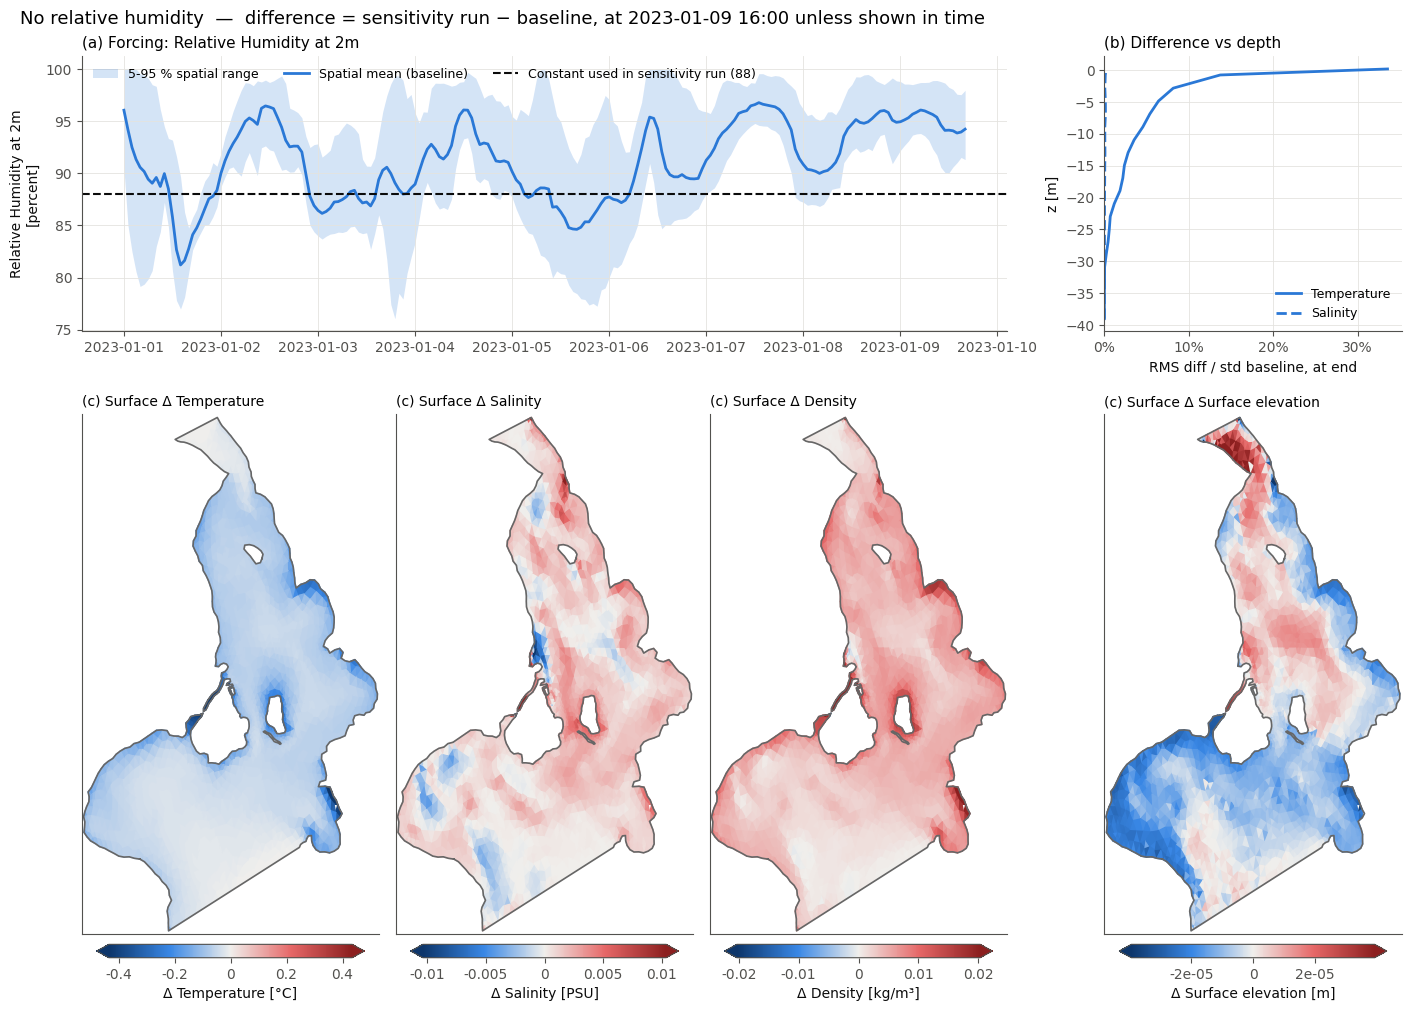

In [40]:
fig = plot_forcing("no_RH2")
plt.show()

#### Clearness (cloud cover)

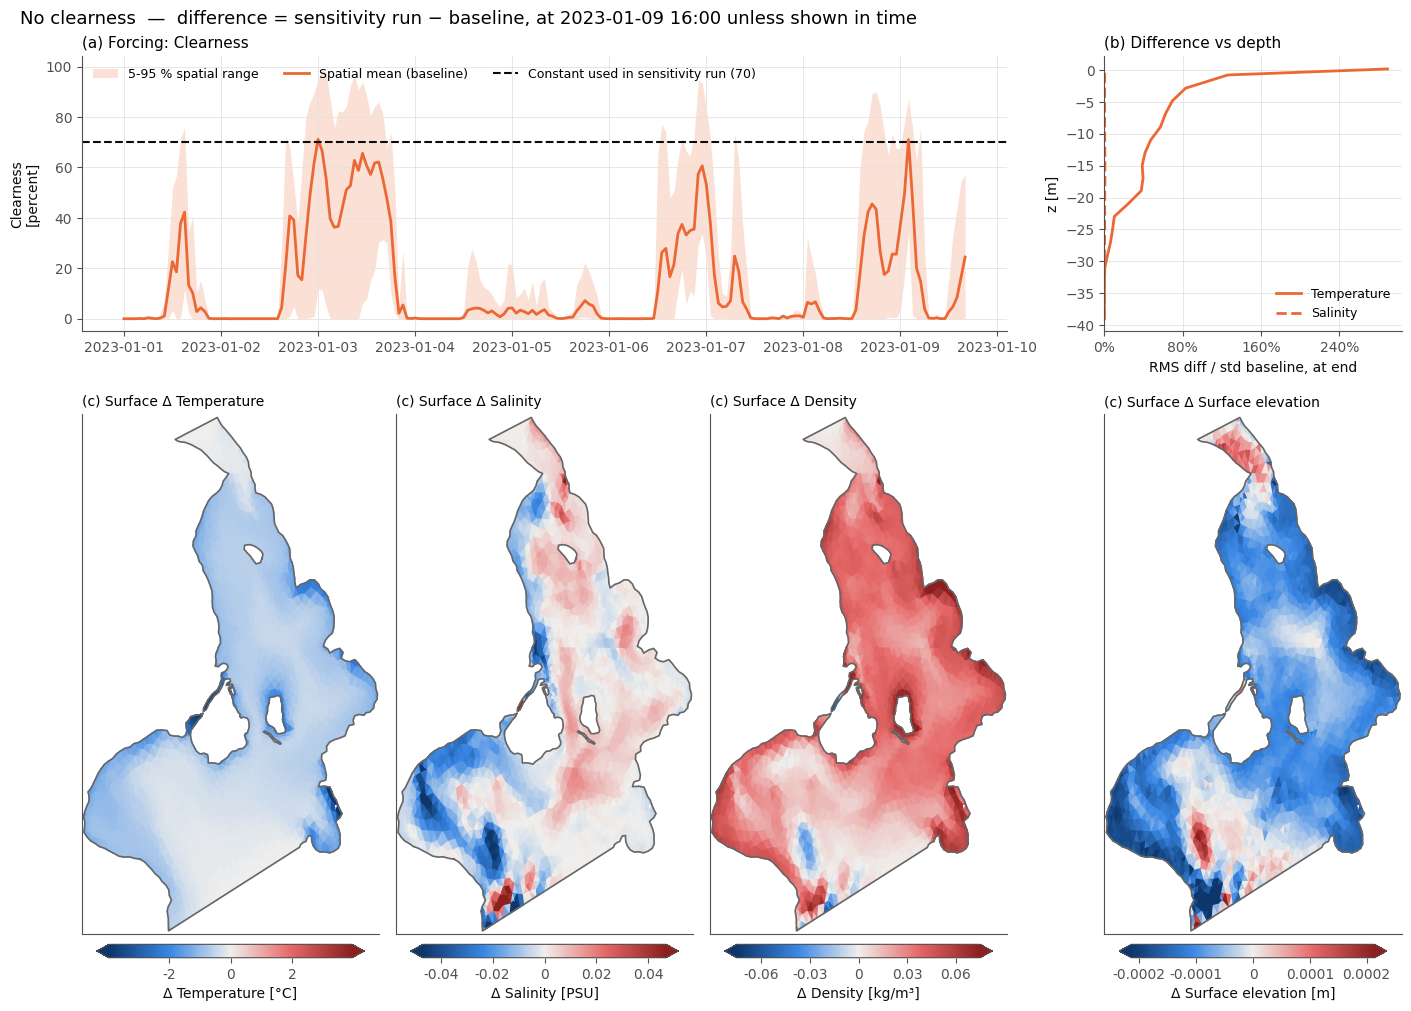

In [41]:
fig = plot_forcing("no_clearness")
plt.show()

#### Precipitation

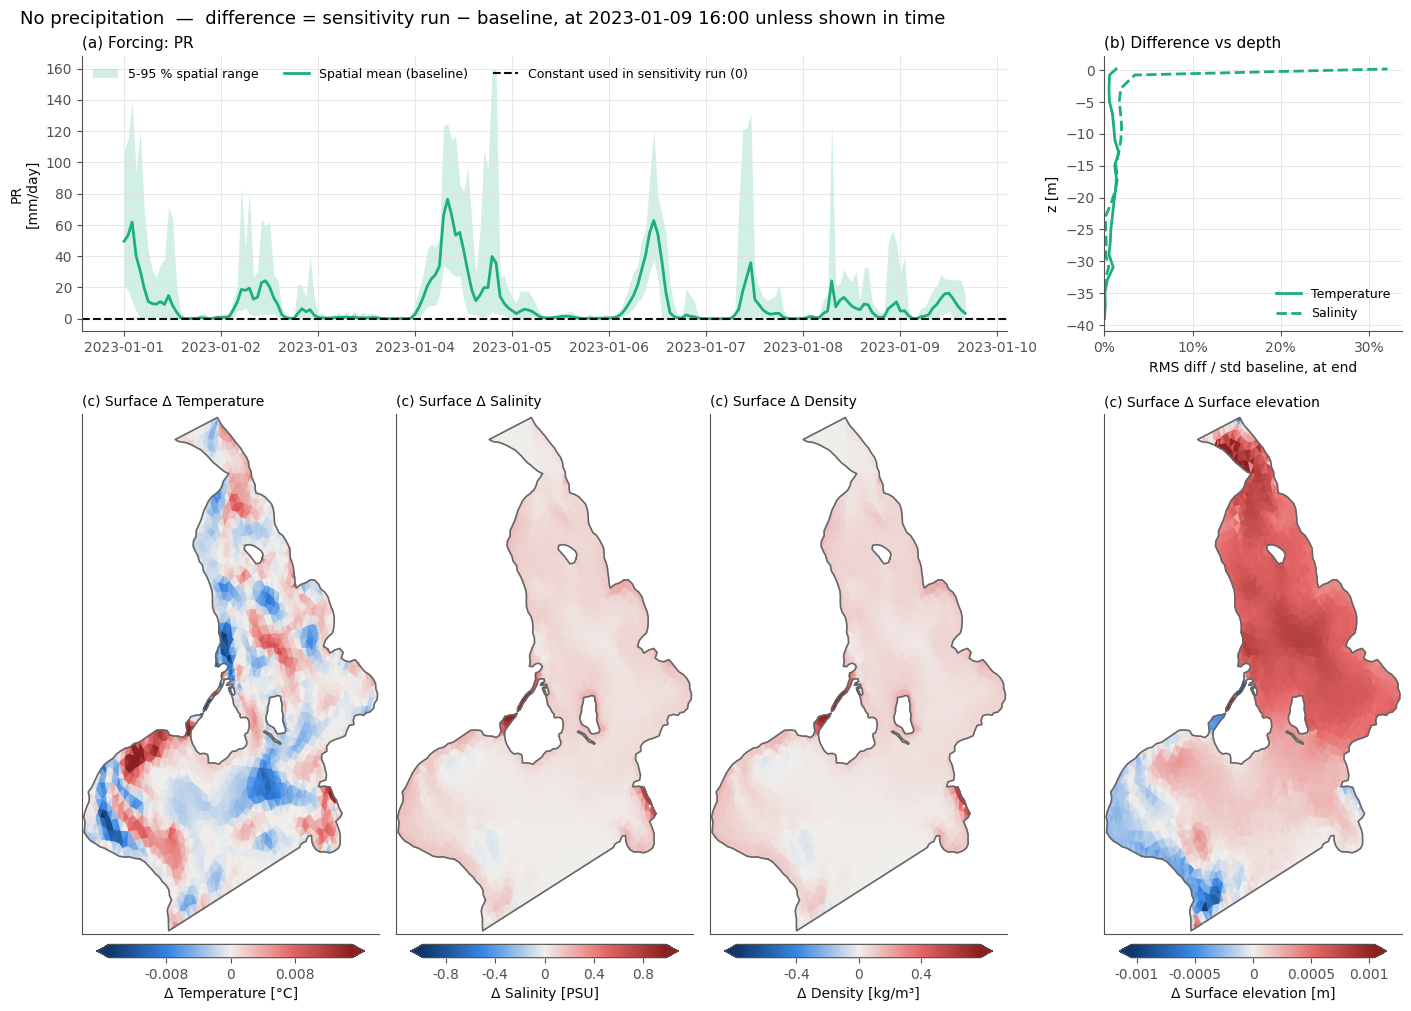

In [42]:
fig = plot_forcing("no_precipitation")
plt.show()